# `HiRef` on MERFISH

## imports

In [1]:
import numpy as np
import pandas as pd
import sklearn.datasets
import sys, time
import torch
import boto3
from io import BytesIO
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

In [2]:
session = boto3.Session(profile_name="802451596237_StorageWorkgroupRW")
s3 = session.client('s3')
bucket_name = 'pga-genomics-wg-802451596237-us-west-2'  

In [3]:
filehandle_hrot = '/allen/programs/celltypes/workgroups/mousecelltypes/Yeganeh/HiRef'
filehandle_nbs = 'ymarghi/Datasets/MERFISH/vizgen/'

In [4]:
sys.path.insert(0, filehandle_hrot)
sys.path.insert(0, filehandle_hrot + '/omt/')
sys.path.insert(0, filehandle_hrot + '/src/')

In [5]:
import importlib
import FRLC
from FRLC import FRLC_opt
import HR_OT
importlib.reload(HR_OT)
import rank_annealing as ra
import util_merfish as um
from functions import sample_gmm_kdim, mmd_rbf, points_transport
from solver import omt, ot_w2, ot_sinkh, shallow_gmm, vectorized_eogt_dist
from omt_vis_tools import plot_gmm_ellipses

W1210 14:45:34.904894   14046 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML library doesn't have required functions.
W1210 14:45:34.905007   14044 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML library doesn't have required functions.
W1210 14:45:34.905043   14045 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML library doesn't have required functions.
W1210 14:45:34.911493 4192395 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML library doesn't have required functions.
W1210 14:45:34.911859 4192395 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML library doesn't have required functions.
W1210 14:45:34.912165 4192395 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML library doesn't have required functions.


In [6]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f'On device: {device}')
dtype = torch.float32

um.set_seed(44)

On device: cuda:0


## load MERFISH spatial data

In [7]:
# contains spatial features
metadata_1 = 'datasets_mouse_brain_map_BrainReceptorShowcase_Slice2_Replicate3_cell_metadata_S2R3.csv'
metadata_2 = 'datasets_mouse_brain_map_BrainReceptorShowcase_Slice2_Replicate2_cell_metadata_S2R2.csv'

# contains expression data
gene_1 = 'datasets_mouse_brain_map_BrainReceptorShowcase_Slice2_Replicate3_cell_by_gene_S2R3.csv'
gene_2 = 'datasets_mouse_brain_map_BrainReceptorShowcase_Slice2_Replicate2_cell_by_gene_S2R2.csv'

obj = s3.get_object(Bucket=bucket_name, Key=filehandle_nbs + metadata_1)
fname1 = BytesIO(obj['Body'].read())
obj = s3.get_object(Bucket=bucket_name, Key=filehandle_nbs + metadata_2)
fname2 = BytesIO(obj['Body'].read())
obj = s3.get_object(Bucket=bucket_name, Key=filehandle_nbs + gene_1)
X_fname1 = BytesIO(obj['Body'].read())
obj = s3.get_object(Bucket=bucket_name, Key=filehandle_nbs + gene_2)
X_fname2 = BytesIO(obj['Body'].read())


Number of cells: 85958


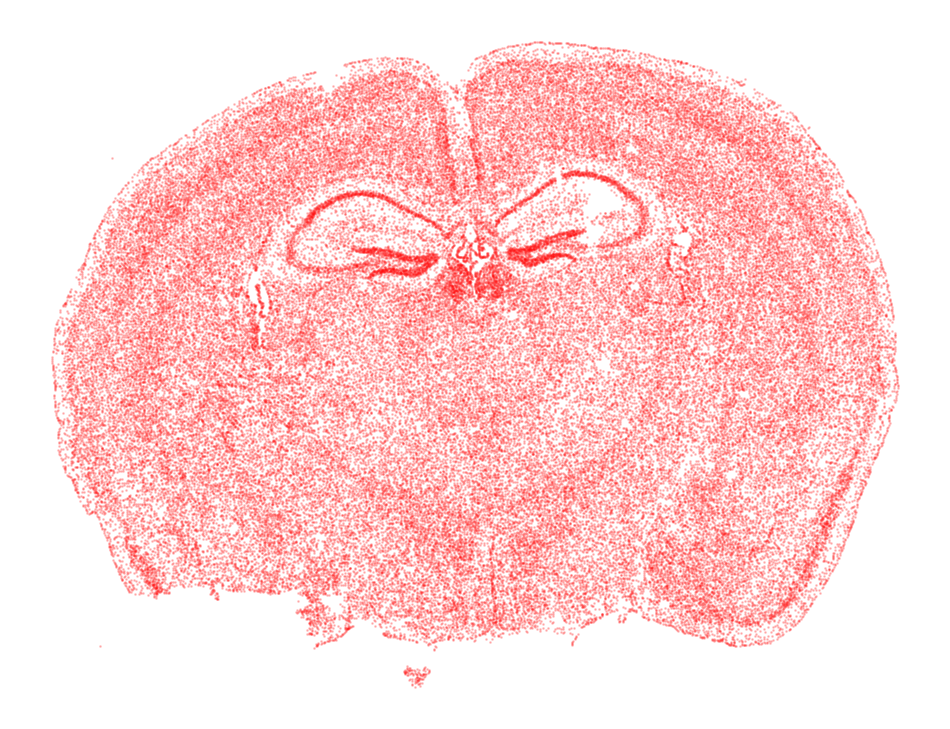

In [14]:
# loading "Slice 2, Replicate 3":
_, _, df1, _, _, xI_c, yI_c, _, _ = um.plot_cell_positions(fname1)

Number of cells: 84172


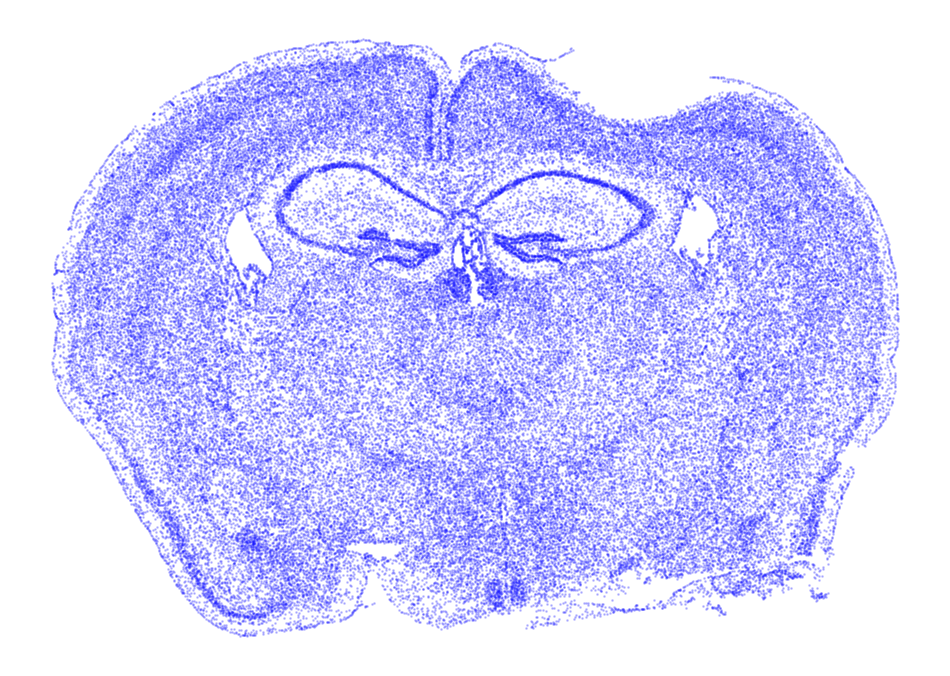

In [9]:
# loading "Slice 2, Replicate 2":
_, _, df2, _, _, _, _, xJ_c_L, yJ_c_L = um.plot_cell_positions(fname2,
                                                               color='blue',
                                                               theta_deg=-45.0)

## centering and rotation of the second slice gives affine registration

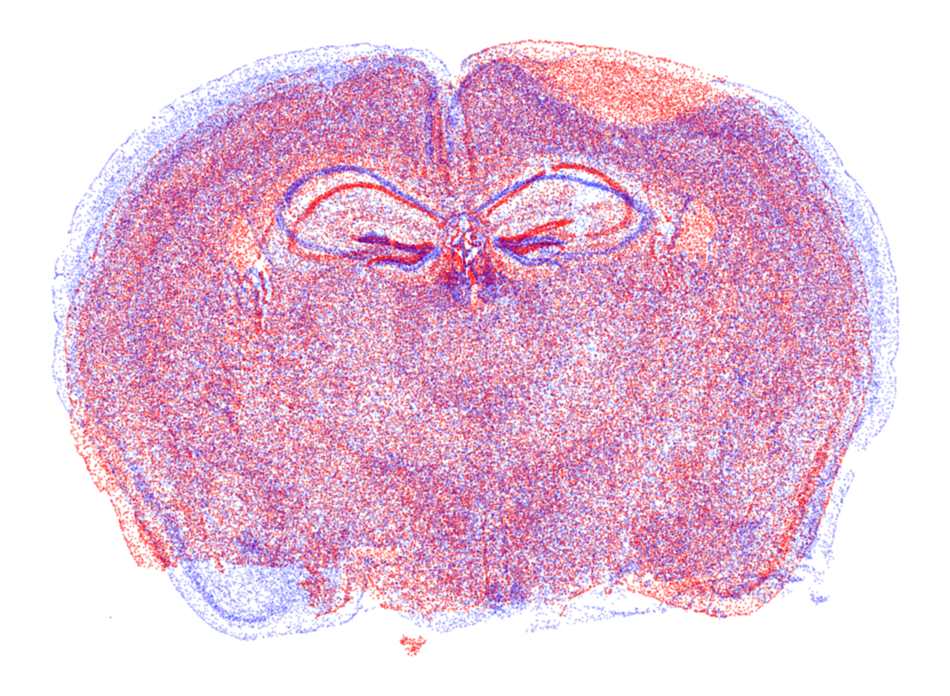

In [10]:
_, _ = um.plot_dual_scatter(xI_c, yI_c, xJ_c_L, yJ_c_L)

## subsample larger slice to make the datasets of equal size

In [11]:
S1 = np.column_stack((xI_c, yI_c))
S2 = np.column_stack((xJ_c_L, yJ_c_L))
print(f"Number of cells in first dataset: {S1.shape[0]}")
print(f"Number of cells in second dataset: {S2.shape[0]}")

# num_to_remove = len(df1) - len(df2)
# print(f"Number of cells to remove from first dataset: {num_to_remove}")
# indices_to_remove = np.random.choice(S1_full.shape[0], num_to_remove, replace=False)
# mask = np.ones(S1_full.shape[0], dtype=bool)
# mask[indices_to_remove] = False
# S1 = S1_full[mask]
# np.save('S1.npy', S1)
# np.save('S2.npy', S2)

Number of cells in first dataset: 85958
Number of cells in second dataset: 84172


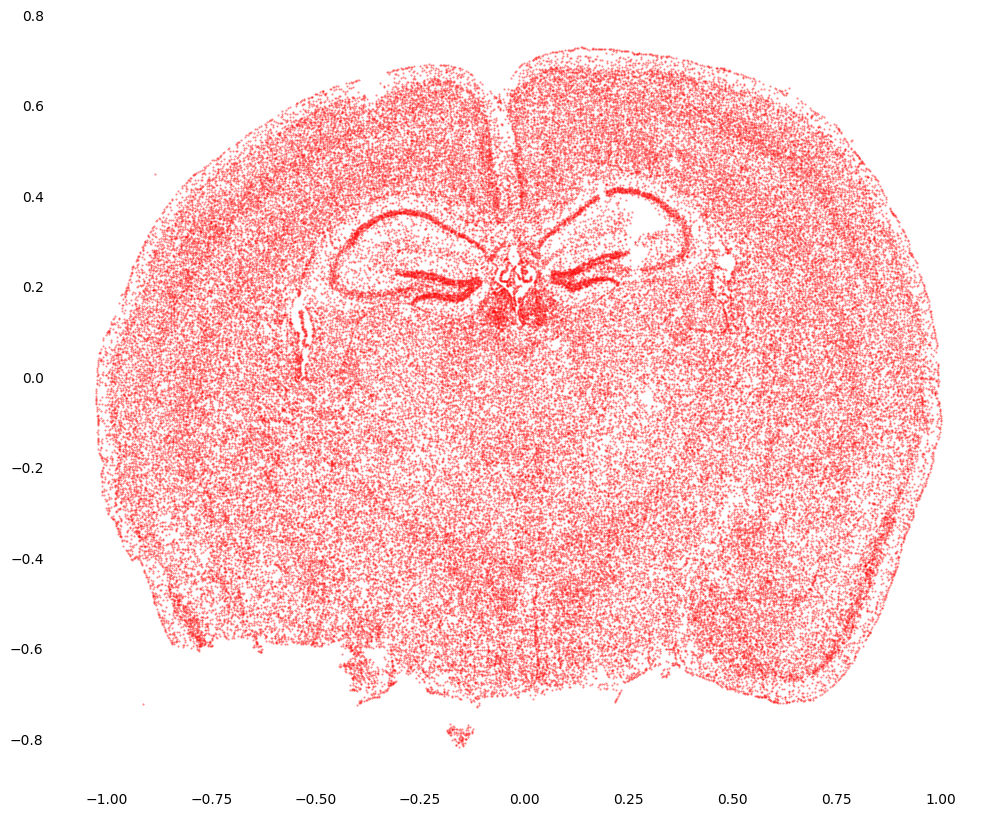

In [12]:
S1_norm = S1 / np.max(S1)
S2_norm = S2 / np.max(S2)

plt.plot(S1_norm[:,0], S1_norm[:,1], 'ro', label='Slice 2, Replicate 3', markersize=0.5, alpha=0.5)

In [13]:
eps = 0.001
max_iter = int(1e6)
stop_thr = 1e-6
Ks = 2000
Kt = 2000
cov_type = 'full'

omt_w, omt_mu, omt_cov, solver_dict = omt(
                                        data_source=S1_norm, 
                                        data_target=S2_norm, 
                                        n_components=(Ks, Kt), 
                                        eps_gmm=eps, 
                                        eps_w=eps, 
                                        method='sinkhorn', 
                                        cov_type=cov_type,
                                        reg_covar=1e-6,
                                        max_iter=max_iter,
                                        stop_thr=stop_thr,
                                        verbose=True,
                                    )

Fitted a GMM with 2000 components.
Model converged: True
Number of iterations: 12
--------------------------------------------------
Fitted a GMM with 2000 components.
Model converged: True
Number of iterations: 12
--------------------------------------------------
Number of components in source GMM: 2000
Number of components in target GMM: 2000
Time taken for GMM fitting: 734.4282371997833 seconds
Total time for vectorized calculation: 3.93 seconds
Total transportation cost: 0.0036415561121810078
Discrepence in marginals' weights: 3.9591244177517654e-18 9.987432529764236e-07
Number of iterations: 3140
Time taken for transportation optimzation: 16.401615142822266 seconds
Number of total iterations: 3164
Total time taken: 750.8298523426056 seconds


In [15]:
# --- Sample from the fitted GMM ---
n_samples = 50000
gmm_s = solver_dict['gmm_s']
gmm_t = solver_dict['gmm_t']

gmm_s_samples, _ = gmm_s.sample(n_samples=n_samples)
gmm_t_samples, _ = gmm_t.sample(n_samples=n_samples)

/allen/programs/celltypes/workgroups/mousecelltypes/Yeganeh/Temp/ipykernel_4114402/2519572402.py:9: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  scatter = ax[0].scatter(S1_norm[:, 0], S1_norm[:, 1], s=marker_size, c=color_source, facecolors=color_source, edgecolors='none', alpha=alpha)
/allen/programs/celltypes/workgroups/mousecelltypes/Yeganeh/Temp/ipykernel_4114402/2519572402.py:22: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax[1].scatter(S1_norm[:, 0], S1_norm[:, 1], s=marker_size, c=color_target, facecolors=color_target, edgecolors='none', alpha=alpha)


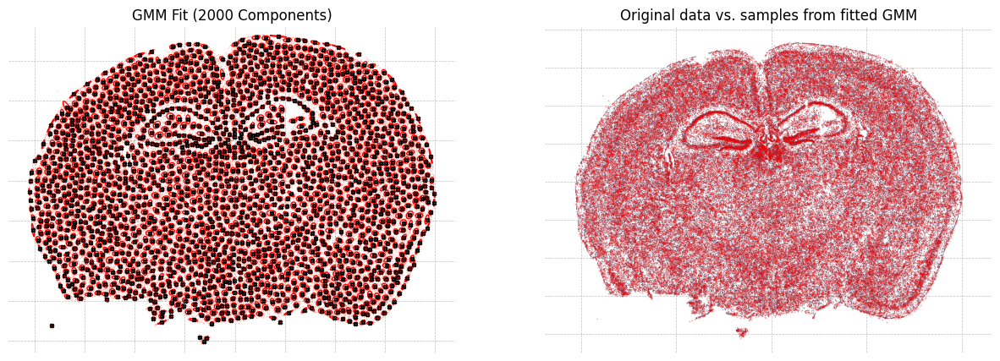

In [16]:
color_source = '#ff715b'
color_target = '#29335C' 
color_omt = '#eeab00'
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

marker_size =.5
alpha = .7
# Plot data points colored by GMM assignment
scatter = ax[0].scatter(S1_norm[:, 0], S1_norm[:, 1], s=marker_size, c=color_source, facecolors=color_source, edgecolors='none', alpha=alpha)
# Plot the GMM component means and ellipses
plot_gmm_ellipses(gmm_s, ax[0], n_std=2.0, edgecolor='red', lw=1, facecolor='none', selected_components=130)
ax[0].scatter(gmm_s.means_[:, 0], gmm_s.means_[:, 1], marker='X', s=10, c='red', edgecolors='black')
ax[0].set_title(f'GMM Fit ({Ks} Components)')
ax[0].axis('equal')
ax[0].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax[0].grid(True, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)
ax[0].spines['top'].set_color('gray')
ax[0].spines['right'].set_color('gray')
ax[0].spines['left'].set_color('gray')
ax[0].spines['bottom'].set_color('gray')

ax[1].scatter(S1_norm[:, 0], S1_norm[:, 1], s=marker_size, c=color_target, facecolors=color_target, edgecolors='none', alpha=alpha)
# Plot samples generated from the GMM
ax[1].scatter(gmm_s_samples[:, 0], gmm_s_samples[:, 1], color='red', s=marker_size, alpha=alpha-.5, label=f'GMM Samples ({Kt} components)')
ax[1].set_title('Original data vs. samples from fitted GMM')
ax[1].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax[1].axis('equal')
ax[1].grid(True, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)
ax[1].spines['top'].set_color('gray')
ax[1].spines['right'].set_color('gray')
ax[1].spines['left'].set_color('gray')
ax[1].spines['bottom'].set_color('gray')
plt.show()

/allen/programs/celltypes/workgroups/mousecelltypes/Yeganeh/Temp/ipykernel_4114402/2640172403.py:9: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  scatter = ax[0].scatter(S2_norm[:, 0], S2_norm[:, 1], s=marker_size, c=color_target, facecolors=color_target, edgecolors='none', alpha=alpha)
/allen/programs/celltypes/workgroups/mousecelltypes/Yeganeh/Temp/ipykernel_4114402/2640172403.py:22: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax[1].scatter(S2_norm[:, 0], S2_norm[:, 1], s=marker_size, c=color_target, facecolors=color_target, edgecolors='none', alpha=alpha)


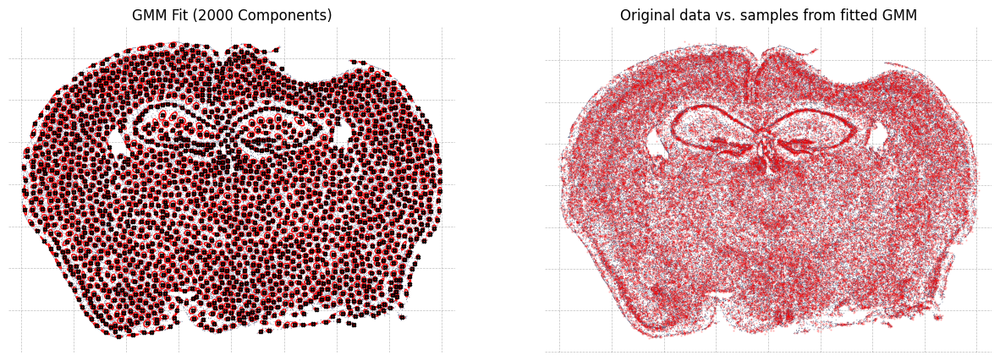

In [17]:
color_source = '#ff715b'
color_target = '#29335C' 
color_omt = '#eeab00'
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

marker_size =.5
alpha = .7
# Plot data points colored by GMM assignment
scatter = ax[0].scatter(S2_norm[:, 0], S2_norm[:, 1], s=marker_size, c=color_target, facecolors=color_target, edgecolors='none', alpha=alpha)
# Plot the GMM component means and ellipses
plot_gmm_ellipses(gmm_t, ax[0], n_std=2.0, edgecolor='red', lw=1, facecolor='none', selected_components=np.argmax(omt_w[130, :]))
ax[0].scatter(gmm_t.means_[:, 0], gmm_t.means_[:, 1], marker='X', s=10, c='red', edgecolors='black')
ax[0].set_title(f'GMM Fit ({Kt} Components)')
ax[0].axis('equal')
ax[0].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax[0].grid(True, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)
ax[0].spines['top'].set_color('gray')
ax[0].spines['right'].set_color('gray')
ax[0].spines['left'].set_color('gray')
ax[0].spines['bottom'].set_color('gray')

ax[1].scatter(S2_norm[:, 0], S2_norm[:, 1], s=marker_size, c=color_target, facecolors=color_target, edgecolors='none', alpha=alpha)
# Plot samples generated from the GMM
ax[1].scatter(gmm_t_samples[:, 0], gmm_t_samples[:, 1], color='red', s=marker_size, alpha=alpha-.5, label=f'GMM Samples ({Kt} components)')
ax[1].set_title('Original data vs. samples from fitted GMM')
ax[1].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax[1].axis('equal')
ax[1].grid(True, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)
ax[1].spines['top'].set_color('gray')
ax[1].spines['right'].set_color('gray')
ax[1].spines['left'].set_color('gray')
ax[1].spines['bottom'].set_color('gray')
plt.show()

In [ ]:
S2_pred = points_transport(S1_norm, omt_w, solver_dict)

/allen/programs/celltypes/workgroups/mousecelltypes/Yeganeh/Temp/ipykernel_4114402/285404189.py:9: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  scatter = ax[0].scatter(S2_norm[:, 0], S2_norm[:, 1], s=marker_size, c=color_target, facecolors=color_target, edgecolors='none', alpha=alpha)
/allen/programs/celltypes/workgroups/mousecelltypes/Yeganeh/Temp/ipykernel_4114402/285404189.py:22: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax[1].scatter(S2_norm[:, 0], S2_norm[:, 1], s=marker_size, c=color_target, facecolors=color_target, edgecolors='none', alpha=alpha)


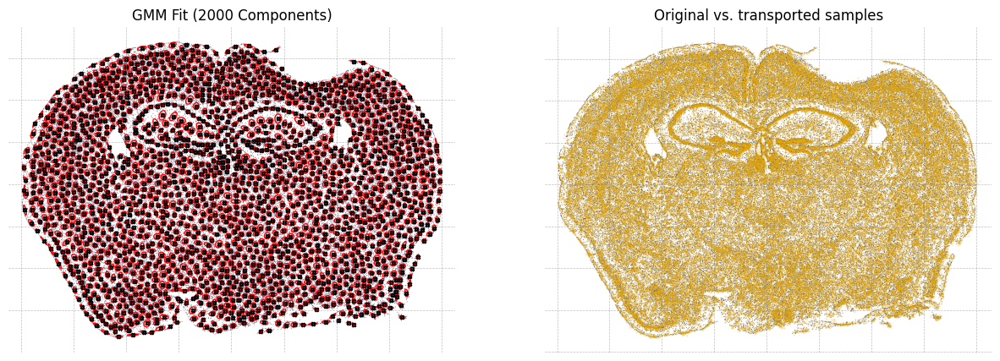

In [19]:
color_source = '#ff715b'
color_target = '#29335C' 
color_omt = '#eeab00'
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

marker_size =.5
alpha = .7
# Plot data points colored by GMM assignment
scatter = ax[0].scatter(S2_norm[:, 0], S2_norm[:, 1], s=marker_size, c=color_target, facecolors=color_target, edgecolors='none', alpha=alpha)
# Plot the GMM component means and ellipses
plot_gmm_ellipses(gmm_t, ax[0], n_std=2.0, edgecolor='red', lw=1, facecolor='none')
ax[0].scatter(gmm_t.means_[:, 0], gmm_t.means_[:, 1], marker='X', s=10, c='red', edgecolors='black')
ax[0].set_title(f'GMM Fit ({Kt} Components)')
ax[0].axis('equal')
ax[0].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax[0].grid(True, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)
ax[0].spines['top'].set_color('gray')
ax[0].spines['right'].set_color('gray')
ax[0].spines['left'].set_color('gray')
ax[0].spines['bottom'].set_color('gray')

ax[1].scatter(S2_norm[:, 0], S2_norm[:, 1], s=marker_size, c=color_target, facecolors=color_target, edgecolors='none', alpha=alpha)
# Plot samples generated from the GMM
ax[1].scatter(S2_pred[:, 0], S2_pred[:, 1], color=color_omt, s=marker_size, alpha=alpha-.5, label=f'GMM Samples ({Kt} components)')
ax[1].set_title('Original vs. transported samples')
ax[1].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax[1].axis('equal')
ax[1].grid(True, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)
ax[1].spines['top'].set_color('gray')
ax[1].spines['right'].set_color('gray')
ax[1].spines['left'].set_color('gray')
ax[1].spines['bottom'].set_color('gray')
plt.show()

In [20]:
X_df_s = pd.read_csv(X_fname1, sep=',', index_col=0)
X_df_t = pd.read_csv(X_fname2, sep=',', index_col=0)

print ('Order of genes matches between source and target datasets?', np.all(X_df_t.keys() == X_df_s.keys()))

Order of genes matches between source and target datasets? True


In [21]:
df_s = pd.DataFrame(S1_norm, columns=['X', 'Y'], index=X_df_s.index)
df_t = pd.DataFrame(S2_norm, columns=['X', 'Y'], index=X_df_t.index)
df_s_tr = pd.DataFrame(S2_pred, columns=['X', 'Y'], index=X_df_s.index)

In [ ]:
genes = list(X_df_s.columns.values)

X_df_transfered = X_df_s.copy()
X_df_s['GMM_Component']  = solver_dict['gmm_s'].predict(S1_norm)
X_df_t['GMM_Component']  = solver_dict['gmm_t'].predict(S2_norm)
X_df_transfered['GMM_Component']  = solver_dict['gmm_t'].predict(S2_pred)

X_df_s[genes] = X_df_s.groupby("GMM_Component")[genes].transform("mean")
X_df_t[genes] = X_df_t.groupby("GMM_Component")[genes].transform("mean")
X_df_transfered[genes] = X_df_transfered.groupby("GMM_Component")[genes].transform("mean")

In [ ]:
# Calculate cosine similarity between true and transferred expression
selected_genes = ["Slc17a7", "Grm4", "Olig1", "Gad1", "Peg10"]

X_df_t_smoothed = X_df_t.copy()
X_df_transfered_smoothed = X_df_transfered.copy()


for gene in selected_genes:
    vec1 = np.zeros((solver_dict['gmm_t'].n_components, 1))
    vec2 = np.zeros((solver_dict['gmm_t'].n_components, 1))
    
    for k in range(solver_dict['gmm_t'].n_components):
        transport_cells = np.where(X_df_transfered['GMM_Component'] == k)[0]
        target_cells = np.where(X_df_t['GMM_Component'] == k)[0]
        # Skip if there are no points in this component to match
        if len(target_cells) == 0 or len(transport_cells) == 0:
            print('No points in component', k)
            continue
        
        X_df_t_smoothed.loc[X_df_t_smoothed.index[target_cells], gene] = X_df_t.loc[X_df_t.index[target_cells], gene].mean()
        X_df_transfered_smoothed.loc[X_df_transfered_smoothed.index[transport_cells], gene] = X_df_transfered.loc[X_df_transfered.index[transport_cells], gene].mean()
        vec1[k] = X_df_t.loc[X_df_t.index[target_cells], gene].mean()
        vec2[k] = X_df_transfered.loc[X_df_transfered.index[transport_cells], gene].mean()
        
    cos_sim = cosine_similarity(vec1.T, vec2.T)
    cos_sim_value = cos_sim[0, 0]
    print(f"Cosine similarity for gene {gene} with component {Kt}: {cos_sim_value:.4f}")


/allen/programs/celltypes/workgroups/mousecelltypes/Yeganeh/Temp/ipykernel_4114402/3722823643.py:11: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  scatter = ax[0].scatter(S2_norm[:, 0], S2_norm[:, 1], s=marker_size, c=clr, facecolors=clr, edgecolors='none', alpha=alpha)
/allen/programs/celltypes/workgroups/mousecelltypes/Yeganeh/Temp/ipykernel_4114402/3722823643.py:23: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  scatter = ax[1].scatter(S2_pred[:, 0], S2_pred[:, 1], s=marker_size, c=clr, facecolors=clr, edgecolors='none', alpha=alpha)


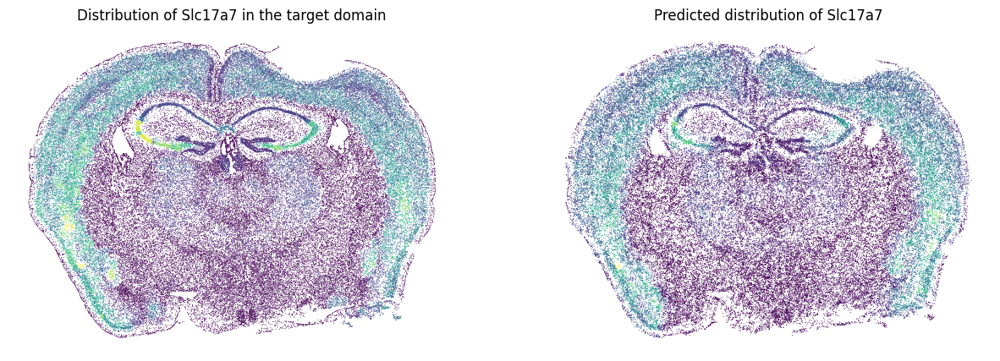

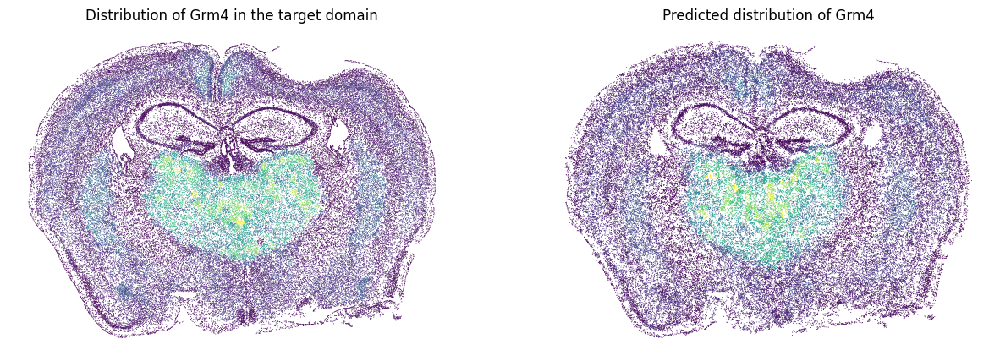

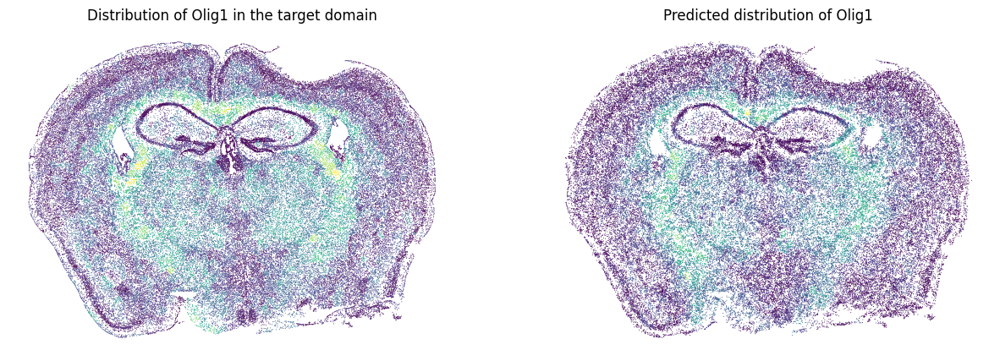

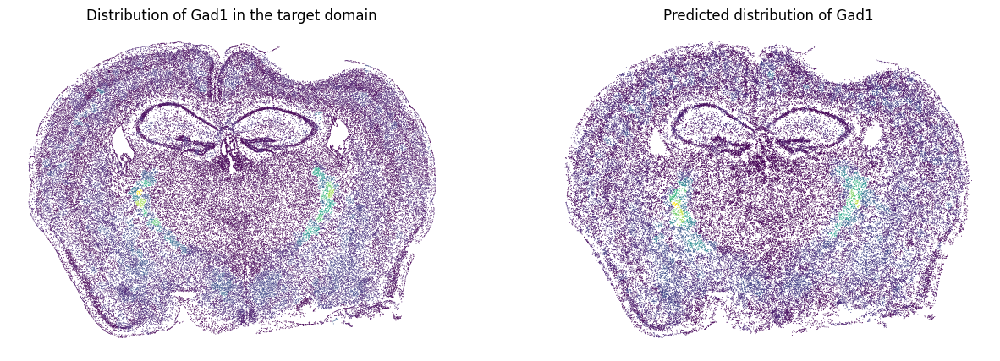

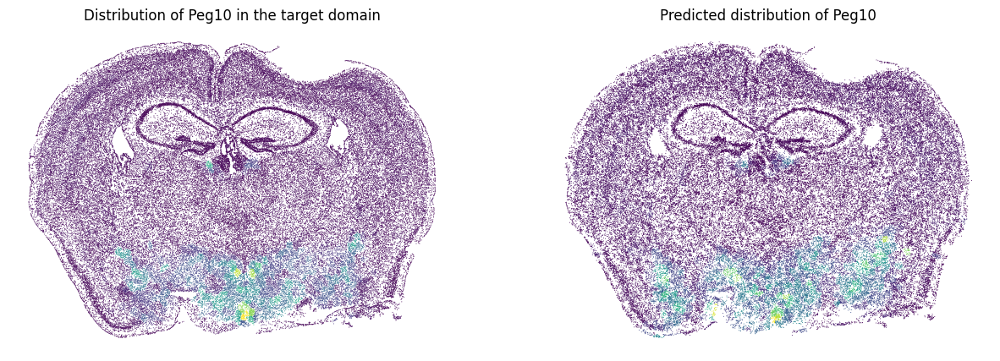

In [67]:
color_source = '#ff715b'
color_target = '#29335C' 
color_omt = '#eeab00'

marker_size =.5
alpha = 1
for gene in selected_genes:
    # Plot data points colored by GMM assignment
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    clr = X_df_t_smoothed[gene] / X_df_t_smoothed[gene].max()
    scatter = ax[0].scatter(S2_norm[:, 0], S2_norm[:, 1], s=marker_size, c=clr, facecolors=clr, edgecolors='none', alpha=alpha)
    ax[0].set_title(f'Distribution of {gene} in the target domain')
    ax[0].axis('off')
    ax[0].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
    ax[0].grid(True, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)
    ax[0].spines['top'].set_color('gray')
    ax[0].spines['right'].set_color('gray')
    ax[0].spines['left'].set_color('gray')
    ax[0].spines['bottom'].set_color('gray')
    # fig.colorbar(scatter, ax=ax[0], fraction=0.046, pad=0.04)

    clr = X_df_transfered_smoothed[gene] / X_df_transfered_smoothed[gene].max()
    scatter = ax[1].scatter(S2_pred[:, 0], S2_pred[:, 1], s=marker_size, c=clr, facecolors=clr, edgecolors='none', alpha=alpha)
    ax[1].set_title(f'Predicted distribution of {gene}')
    ax[1].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
    ax[1].axis('off')
    ax[1].grid(True, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)
    ax[1].spines['top'].set_color('gray')
    ax[1].spines['right'].set_color('gray')
    ax[1].spines['left'].set_color('gray')
    ax[1].spines['bottom'].set_color('gray')
    # fig.colorbar(scatter, ax=ax[1], fraction=0.046, pad=0.04)

    plt.show()

In [39]:
def spatial_avg(X_df, df_coords, gene, num_bins_x=100, num_bins_y=100):

    df_coords['x_bin'] = pd.cut(df_coords['X'], bins=num_bins_x, labels=False)
    df_coords['y_bin'] = pd.cut(df_coords['Y'], bins=num_bins_y, labels=False)

    # 2) Group by (x_bin, y_bin) and compute mean expression in each bin
    #    We'll first combine coords+counts in a single DataFrame
    df_all = pd.concat([df_coords, X_df], axis=1)

    # We'll group by the bin indices:
    grouped = df_all.groupby(['x_bin', 'y_bin'])

    # Then compute the mean expression across all genes:
    bin_means = grouped[X_df.columns].mean()  # DataFrame indexed by (x_bin, y_bin)

    # 3) Map each cell’s bin back to the mean expression
    #    We can merge or reindex by (x_bin, y_bin).
    df_coords2 = df_coords.copy()
    df_coords2['x_bin_y_bin'] = list(zip(df_coords2['x_bin'], df_coords2['y_bin']))

    # bin_means is indexed by (x_bin, y_bin); we align on that:
    bin_means.index = bin_means.index.set_names(['x_bin', 'y_bin'])
    bin_means = bin_means.reset_index()  # turn multi-index into columns for merging
    bin_means['x_bin_y_bin'] = list(zip(bin_means['x_bin'], bin_means['y_bin']))

    # Merge each cell with the average expression of its bin
    df_smoothed = pd.merge(
        df_coords2[['x_bin_y_bin']],
        bin_means.drop(['x_bin', 'y_bin'], axis=1),
        on='x_bin_y_bin',
        how='left'
    )
    df_smoothed.index = df_coords2.index  # restore original cell index

    # df_smoothed now has the "smoothed" expression for each cell in X_df.columns
    smoothed_counts = df_smoothed[X_df.columns]

    # 4) For a single gene, e.g. "Grm4", you can see its smoothed version:
    smoothed_gene = smoothed_counts[gene]
    return smoothed_gene

In [61]:
source_smoothed = spatial_avg(
                            X_df_s[[selected_genes[0]]],  # note the double brackets → keeps it as DataFrame
                            df_s, 
                            gene=selected_genes[0], 
                            num_bins_x=50, 
                            num_bins_y=50,
                                    )
print(source_smoothed.min(), source_smoothed.max())

0.0 142.02355945505158


In [63]:
target_smoothed = spatial_avg(
                            X_df_t[[selected_genes[-1]]],  # note the double brackets → keeps it as DataFrame
                            df_t, 
                            gene=selected_genes[-1], 
                            num_bins_x=50, 
                            num_bins_y=50,
                                    )
print(target_smoothed.min(), target_smoothed.max())

0.0 33.37521469758312


In [42]:
source_smoothed.min(), source_smoothed.max()

(np.float64(0.0), np.float64(21.526329570981655))

In [34]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate cosine similarity between true and transferred expression
genes = ["Slc17a7", "Grm4", "Olig1", "Gad1", "Peg10"]
bin_size = 75

for gene in genes:
    
    source_smoothed = spatial_avg(
                            X_df_s_[[gene]],  # note the double brackets → keeps it as DataFrame
                            df_s_, 
                            gene=gene, 
                            num_bins_x=bin_size, 
                            num_bins_y=bin_size,
                                    )
    target_smoothed = spatial_avg(
                            X_df_t_[[gene]],  # note the double brackets → keeps it as DataFrame
                            df_t_, 
                            gene=gene, 
                            num_bins_x=bin_size, 
                            num_bins_y=bin_size,
                                    )
    
    transported_smoothed = spatial_avg(
                            X_df_s_tr_[[gene]],  # note the double brackets → keeps it as DataFrame
                            df_s_tr_, 
                            gene=gene, 
                            num_bins_x=bin_size, 
                            num_bins_y=bin_size,
                                    )
    
    vec1 = transported_smoothed.values.reshape(1, -1)
    vec2 = target_smoothed.values.reshape(1, -1)
    cos_sim = cosine_similarity(vec1, vec2)
    cos_sim_value = cos_sim[0, 0]
    print(f"Cosine similarity for gene {gene}: {cos_sim_value:.4f}")
    


Cosine similarity for gene Slc17a7: 0.1457
Cosine similarity for gene Grm4: 0.1583
Cosine similarity for gene Olig1: 0.2139
Cosine similarity for gene Gad1: 0.1287
Cosine similarity for gene Peg10: 0.1197


In [86]:
def spatial_avg(X_df, S, gene, num_bins_x=100, num_bins_y=100):

    x_min, x_max = S[:, 0].min(), S[:, 0].max()
    y_min, y_max = S[:, 1].min(), S[:, 1].max()

    df_coords = pd.DataFrame({
        'x': S[:, 0],
        'y': S[:, 1]
    }, index=X_df.index)  # ensure the same index

    df_coords['x_bin'] = pd.cut(df_coords['x'], bins=num_bins_x, labels=False)
    df_coords['y_bin'] = pd.cut(df_coords['y'], bins=num_bins_y, labels=False)

    # 2) Group by (x_bin, y_bin) and compute mean expression in each bin
    #    We'll first combine coords+counts in a single DataFrame
    df_all = pd.concat([df_coords, X_df], axis=1)

    # We'll group by the bin indices:
    grouped = df_all.groupby(['x_bin', 'y_bin'])

    # Then compute the mean expression across all genes:
    bin_means = grouped[X_df.columns].mean()  # DataFrame indexed by (x_bin, y_bin)

    # 3) Map each cell’s bin back to the mean expression
    #    We can merge or reindex by (x_bin, y_bin).
    df_coords2 = df_coords.copy()
    df_coords2['x_bin_y_bin'] = list(zip(df_coords2['x_bin'], df_coords2['y_bin']))

    # bin_means is indexed by (x_bin, y_bin); we align on that:
    bin_means.index = bin_means.index.set_names(['x_bin', 'y_bin'])
    bin_means = bin_means.reset_index()  # turn multi-index into columns for merging
    bin_means['x_bin_y_bin'] = list(zip(bin_means['x_bin'], bin_means['y_bin']))

    # Merge each cell with the average expression of its bin
    df_smoothed = pd.merge(
        df_coords2[['x_bin_y_bin']],
        bin_means.drop(['x_bin', 'y_bin'], axis=1),
        on='x_bin_y_bin',
        how='left'
    )
    df_smoothed.index = df_coords2.index  # restore original cell index

    # df_smoothed now has the "smoothed" expression for each cell in X_df.columns
    smoothed_counts = df_smoothed[X_df.columns]

    # 4) For a single gene, e.g. "Grm4", you can see its smoothed version:
    smoothed_gene = smoothed_counts[gene]
    return smoothed_gene


In [93]:
source_smoothed = spatial_avg(
    X_df_s[[genes[0]]],  # note the double brackets → keeps it as DataFrame
    S1_norm, 
    gene=genes[0], 
    num_bins_x=75, 
    num_bins_y=75
)


In [2]:
import numpy as np
import os
import pandas as pd

results_path = filehandle_hrot + "/results/"

all_files = os.listdir(results_path)

for file in all_files:
    print(file)
    df = pd.read_csv(os.path.join(results_path, file))
    print(df)

merfish_omt_summary_500_500.csv
      Gene  Cosine_Similarity   Ks   Kt     Tcost    euc_cost  n_iter  \
0  Slc17a7           0.934673  500  500  1.098096  113.749197    3570   
1     Grm4           0.941701  500  500  1.098096  113.749197    3570   
2    Olig1           0.927647  500  500  1.098096  113.749197    3570   
3     Gad1           0.814282  500  500  1.098096  113.749197    3570   
4    Peg10           0.818408  500  500  1.098096  113.749197    3570   

   total_iter  time_elapsed_sec  
0        3591        210.410258  
1        3591        210.410258  
2        3591        210.410258  
3        3591        210.410258  
4        3591        210.410258  
merfish_omt_summary_2500_2500.csv
      Gene  Cosine_Similarity    Ks    Kt     Tcost  n_iter  total_iter  \
0  Slc17a7           0.866133  2500  2500  1.004976    3070        3095   
1     Grm4           0.881463  2500  2500  1.004976    3070        3095   
2    Olig1           0.833347  2500  2500  1.004976    3070       